### 記述子・目的変数生成

目的：観測データと未知データ（として利用する）の生成、保存と可視化。

このscript内でデータを生成し、"../data_calculated"ディレクトリに保存します。

目的変数$y$にガウス分布$N(0,\sigma^2)$を加えています。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# pandasの表示optionの設定
pd.set_option("display.max_rows", 20)
pd.set_option("display.max_columns", 50)

#### データ取得
データの作成を行います。

In [2]:
def makedata1(filename, x, obs_frac=0.6, scale=0.1):
    """データ作成

    Args:
        filename (str): ファイル名
        x (np.ndarray): x
        obs_frac (float): 観測データの割合
        scale (float, optional): scale of random.normal. Defaults to 0.1.

    Returns:
        pd.DataFrame: 観測データ
    """
    
    x2 = x*x
    x3 = x**3
    x4 = x**4
    x5 = x**5
    x6 = np.sin(x)
    y = np.sin(x) + np.random.normal(scale=scale, size=x.shape[0])

    df = pd.DataFrame({"x1": x, "x2": x2, "x3": x3,
                       "x4": x4, "x5": x5, "x6": x6, "y": y})
    
    nobs = int(df.shape[0]*obs_frac)
   
    return df.iloc[:nobs,:], df.iloc[nobs:,:]


In [3]:
g_filename = "../data_calculated/x5_sin.csv"
g_filename_new = "../data_calculated/x5_sin_new.csv"

g_df_obs, g_df_new = makedata1(g_filename, 
                               x = np.arange(0.0, 10.0, 0.1), 
                               obs_frac=0.6, scale=0.01)
g_df_obs.to_csv(g_filename, index=False) # この場合はindexに意味が無いので書かない。
g_df_new.to_csv(g_filename_new, index=False) # この場合はindexに意味が無いので書かない。


In [4]:
# 作成したファイルの表示
# indexが無い。
! cat ../data_calculated/x5_sin.csv

x1,x2,x3,x4,x5,x6,y
0.0,0.0,0.0,0.0,0.0,0.0,0.02606937712038688
0.1,0.010000000000000002,0.0010000000000000002,0.00010000000000000002,1.0000000000000003e-05,0.09983341664682815,0.09757127007721789
0.2,0.04000000000000001,0.008000000000000002,0.0016000000000000003,0.0003200000000000001,0.19866933079506122,0.1809049500813265
0.30000000000000004,0.09000000000000002,0.027000000000000014,0.008100000000000005,0.0024300000000000016,0.2955202066613396,0.2726074315104282
0.4,0.16000000000000003,0.06400000000000002,0.025600000000000005,0.010240000000000003,0.3894183423086505,0.39648627583781404
0.5,0.25,0.125,0.0625,0.03125,0.479425538604203,0.4907208002120288
0.6000000000000001,0.3600000000000001,0.2160000000000001,0.12960000000000008,0.07776000000000005,0.5646424733950355,0.5774346606113199
0.7000000000000001,0.4900000000000001,0.3430000000000001,0.2401000000000001,0.16807000000000008,0.6442176872376911,0.6297201461246037
0.8,0.6400000000000001,0.5120000000000001,0.4096000000000001,0.327680000

In [5]:
# dfの表示
g_df_obs

,x1,x2,x3,x4,x5,x6,y
0,0.0,0.00,0.000,0.0000,0.00000,0.000000,0.026069
1,0.1,0.01,0.001,0.0001,0.00001,0.099833,0.097571
2,0.2,0.04,0.008,0.0016,0.00032,0.198669,0.180905
3,0.3,0.09,0.027,0.0081,0.00243,0.295520,0.272607
4,0.4,0.16,0.064,0.0256,0.01024,0.389418,0.396486
...,...,...,...,...,...,...,...
55,5.5,30.25,166.375,915.0625,5032.84375,-0.705540,-0.682665
56,5.6,31.36,175.616,983.4496,5507.31776,-0.631267,-0.633627
57,5.7,32.49,185.193,1055.6001,6016.92057,-0.550686,-0.550057
58,5.8,33.64,195.112,1131.6496,6563.56768,-0.464602,-0.456327


## データ可視化

意図通りにデータ生成できたのかの確認を行う。

In [6]:
g_df = pd.concat([g_df_obs, g_df_new], axis=0).reset_index(drop=True)

<Axes: >

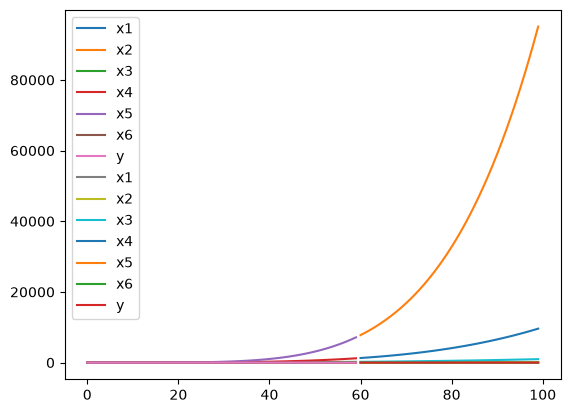

In [7]:
g_fig, g_ax = plt.subplots()
g_df_obs.plot(ax=g_ax)
g_df_new.plot(ax=g_ax)

目的変数は乱数でノイズを入れているので単純なsin関数ではない。

<Axes: xlabel='x1', ylabel='y'>

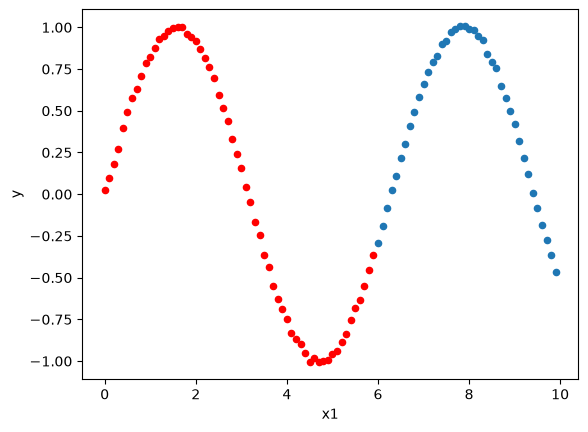

In [8]:
g_fig, g_ax = plt.subplots()
g_df_obs.plot.scatter(x="x1", y="y",color="red",ax=g_ax)
g_df_new.plot.scatter(x="x1", y="y",ax=g_ax)

In [9]:
#### 別データの作成

In [10]:
g_filename = "../data_calculated/x5_sin_noise.csv"
g_filename_new = "../data_calculated/x5_sin_noise_new.csv"

g_df_obs, g_df_new = makedata1(g_filename, 
                               x = np.arange(0.0, 10.0, 0.1), 
                               obs_frac=0.6, scale=0.1)
g_df_obs.to_csv(g_filename, index=False) # この場合はindexに意味が無いので書かない。
g_df_new.to_csv(g_filename_new, index=False) # この場合はindexに意味が無いので書かない。


<Axes: xlabel='x1', ylabel='y'>

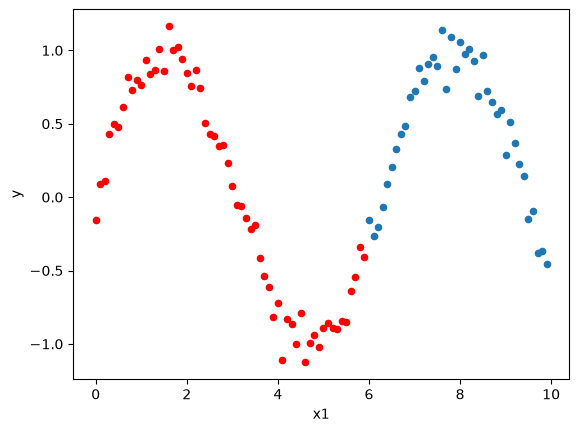

In [11]:
g_fig, g_ax = plt.subplots()
g_df_obs.plot.scatter(x="x1", y="y",color="red",ax=g_ax)
g_df_new.plot.scatter(x="x1", y="y",ax=g_ax)

#### 別データの作成

In [12]:
def makedata2(filename, x, obs_frac=0.6, scale=0.1):
    """データ作成

    Args:
        filename (str): file name
        obs_frac (float): 観測データの割合
        scale (float, optional): scale of random.normal. Defaults to 0.1.

    Returns:
        pd.DataFrame: data
    """
    x2 = x*x
    x3 = x+x2

    y = x3
    ymax = np.max(y)
    y = y/ymax + np.random.normal(scale=scale, size=x.shape[0])

    df = pd.DataFrame({"x1": x, "x2": x2, "x3": x3,
                       "y": y})

    nobs = int(df.shape[0]*obs_frac)
    return df.iloc[:nobs, :], df.iloc[nobs:, :]


In [13]:
g_df_obs, g_df_new = makedata2(g_filename, x = np.arange(0.0, 10.0, 0.1), obs_frac=0.6,  scale= 0.01)
g_filename = "../data_calculated/x123.csv"
g_filename_new = "../data_calculated/x123_new.csv"
g_df_obs.to_csv(g_filename, index=False)
g_df_new.to_csv(g_filename_new, index=False)

<Axes: >

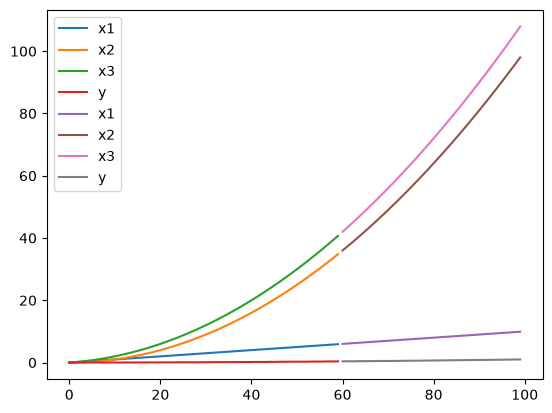

In [14]:
g_fig, g_ax = plt.subplots()
g_df_obs.plot(ax=g_ax)
g_df_new.plot(ax=g_ax)

<Axes: xlabel='x1', ylabel='y'>

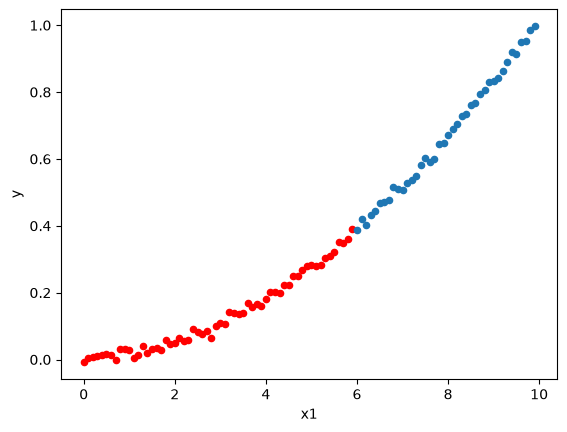

In [15]:
g_fig, g_ax = plt.subplots()
g_df_obs.plot.scatter(x="x1", y="y",color="red", ax=g_ax)
g_df_new.plot.scatter(x="x1", y="y",ax=g_ax)

以下ではこのスクリプトで作成したデータを用います。